In [1]:
# ============================================================
# Cell 1 — Install packages
# ============================================================
!pip install -q -U timm "huggingface_hub<2.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 30.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 26.2 MB/s eta 0:00:00


In [2]:
# ============================================================
# Cell 2 — Imports, reproducibility, device
# ============================================================
import os, glob, json, math, time, random, warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image, ImageFile
import timm
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score
import matplotlib.pyplot as plt

ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore")

def seed_everything(seed=42):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| timm", timm.__version__, "| device", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

torch 2.11.0+cu128 | timm 1.0.30 | device cuda
GPU: Tesla T4


In [3]:
# ============================================================
# Cell 3 — Locate input datasets
# ============================================================
def find_input_dir(slug, base="/kaggle/input", max_depth=4):
    """Find a Kaggle dataset folder by its slug, whatever the mount layout."""
    base_depth = base.rstrip("/").count("/")
    for root, dirs, _ in os.walk(base):
        if os.path.basename(root) == slug:
            return root
        if root.count("/") - base_depth >= max_depth:
            dirs[:] = []
    raise FileNotFoundError(f"Dataset '{slug}' not found under {base}. Add it as input.")

for slug in ["edda-train-val-test-splits", "edda-d1-odir5k-clean",
             "edda-d2-mured-clean", "edda-d3-rfmid-clean"]:
    print(f"{slug:28s} -> {find_input_dir(slug)}")

edda-train-val-test-splits   -> /kaggle/input/datasets/bisusiddharth/edda-train-val-test-splits
edda-d1-odir5k-clean         -> /kaggle/input/datasets/bisusiddharth/edda-d1-odir5k-clean
edda-d2-mured-clean          -> /kaggle/input/datasets/bisusiddharth/edda-d2-mured-clean
edda-d3-rfmid-clean          -> /kaggle/input/datasets/bisusiddharth/edda-d3-rfmid-clean


In [4]:
# ============================================================
# Cell 4 — Configuration (the only cell to edit)
# ============================================================
# ---------------- Experiment ----------------
EXPERIMENT    = "D123"                     # train on ODIR + MuReD + RFMiD
TRAIN_SOURCES = ["D1", "D2", "D3"]
QUICK_TEST    = False                       # True = 2-epoch check; False = full training
MODEL_NAME    = "ResNet50"

# ---------------- Data ----------------
SPLITS_SLUG  = "edda-train-val-test-splits"
IMAGE_SLUGS  = {"D1": "edda-d1-odir5k-clean",   # ODIR-5K
                "D2": "edda-d2-mured-clean",    # MuReD
                "D3": "edda-d3-rfmid-clean"}    # RFMiD
ALL_SOURCES  = list(IMAGE_SLUGS)
FILE_COL, SOURCE_COL, PATH_COL, SPLIT_COL = "filename", "source_dataset", "image_path", "split"
CLASSES      = ["Normal", "DR", "Glaucoma", "AMD", "Myopia"]
DISEASE_CLASSES = [c for c in CLASSES if c != "Normal"]

# ---------------- Backbone ----------------
CNN_ARCH = "resnet50.a1_in1k"              # same ImageNet weights as the fusion models' CNN branch

# ---------------- Training (matched to the other experiments) ----------------
IMG_SIZE      = 224
BATCH_SIZE    = 32
ACCUM_STEPS   = 1                          # effective batch = 32 (same as other runs)
EPOCHS        = 2 if QUICK_TEST else 30
WARMUP_EPOCHS = 1 if QUICK_TEST else 5
BASE_LR       = 3.125e-4                   # = ResNet-50 branch peak LR in the fusion models
MIN_LR        = 1e-6
WEIGHT_DECAY  = 0.05
CNN_DROP_PATH = 0.05
PATIENCE      = 8                          # early stopping on val macro-AUC
NUM_WORKERS   = 4
SEED          = 42

# ---------------- Output ----------------
RUN_DIR = f"/kaggle/working/ResNet50_{EXPERIMENT}" + ("_quicktest" if QUICK_TEST else "")
os.makedirs(RUN_DIR, exist_ok=True)
BEST_CHECKPOINT = f"{RUN_DIR}/resnet50_{EXPERIMENT}_best.pth"

seed_everything(SEED)
print(f"{MODEL_NAME} | train on {EXPERIMENT} {TRAIN_SOURCES} | epochs {EPOCHS} "
      f"| peak LR {BASE_LR:.2e} | quick_test={QUICK_TEST}\nOutputs -> {RUN_DIR}")

ResNet50 | train on D123 ['D1', 'D2', 'D3'] | epochs 30 | peak LR 3.13e-04 | quick_test=False
Outputs -> /kaggle/working/ResNet50_D123


In [5]:
# ============================================================
# Cell 5 — Build train/val/test splits + leakage check
# ============================================================
SPLITS_DIR = find_input_dir(SPLITS_SLUG)

def load_split_csv(source):
    hits = glob.glob(f"{SPLITS_DIR}/**/split_{source}.csv", recursive=True)
    assert hits, f"split_{source}.csv not found in {SPLITS_DIR}"
    return pd.read_csv(hits[0])

_image_index = None
def get_image_index():
    """filename -> full path across all image datasets (fallback for stale paths)."""
    global _image_index
    if _image_index is None:
        _image_index = {}
        for slug in IMAGE_SLUGS.values():
            for root, _, files in os.walk(find_input_dir(slug)):
                for f in files:
                    _image_index.setdefault(f, os.path.join(root, f))
    return _image_index

def clean_split(df, source):
    df = df.copy()
    df[CLASSES] = df[CLASSES].fillna(0).astype(int).clip(0, 1)
    exists = df[PATH_COL].map(os.path.exists)
    if not exists.all():
        print(f"[{source}] {(~exists).sum()} stored paths missing, resolving by filename...")
        df.loc[~exists, PATH_COL] = df.loc[~exists, FILE_COL].map(get_image_index())
    n_missing = df[PATH_COL].isna().sum()
    if n_missing:
        print(f"[{source}] WARNING: {n_missing} images not found, dropped")
    df = df.dropna(subset=[PATH_COL]).reset_index(drop=True)
    df["img_path"] = df[PATH_COL]
    return df

# Clean per-source splits (the combined split_D12/D123 files are NOT used: they leak)
per_source = {s: clean_split(load_split_csv(s), s) for s in ALL_SOURCES}
for s, d in per_source.items():
    assert d.groupby(FILE_COL)[SPLIT_COL].nunique().max() == 1, f"{s}: image in >1 split"

def select(split, sources):
    return pd.concat([per_source[s][per_source[s][SPLIT_COL] == split] for s in sources],
                     ignore_index=True)

train_df = select("train", TRAIN_SOURCES)
val_df   = select("val",   TRAIN_SOURCES)

# Test sets — names identical to the RETFound run so results can be paired
TEST_SETS = {f"{EXPERIMENT}_in_domain": select("test", TRAIN_SOURCES)}
for s in ALL_SOURCES:
    TEST_SETS[f"{s}_test"] = select("test", [s])
DOMAIN = {f"{s}_test": ("in-domain" if s in TRAIN_SOURCES else "OUT-OF-DOMAIN") for s in ALL_SOURCES}
DOMAIN[f"{EXPERIMENT}_in_domain"] = "in-domain (pooled)"

# Leakage check
seen_files = set(train_df[FILE_COL]) | set(val_df[FILE_COL])
for name, d in TEST_SETS.items():
    assert not d[FILE_COL].isin(seen_files).any(), f"LEAKAGE detected in {name}"
assert not set(train_df[FILE_COL]) & set(val_df[FILE_COL]), "train/val overlap"
print("Leakage check passed: train, val and test are disjoint.\n")

data_summary = pd.DataFrame({n: d[CLASSES].sum() for n, d in
                             [("train", train_df), ("val", val_df)] + list(TEST_SETS.items())})
data_summary.loc["N images"] = [len(train_df), len(val_df)] + [len(d) for d in TEST_SETS.values()]
display(data_summary)
data_summary.to_csv(f"{RUN_DIR}/data_summary.csv")
print("Train by source:", train_df[SOURCE_COL].value_counts().to_dict())

Leakage check passed: train, val and test are disjoint.



,train,val,D123_in_domain,D1_test,D2_test,D3_test
Normal,2773,595,595,431,64,100
DR,1865,398,398,241,63,94
Glaucoma,672,142,143,43,33,67
AMD,402,84,86,40,20,26
Myopia,335,72,70,35,11,24
N images,5882,1259,1260,790,182,288


Train by source: {'D1': 3682, 'D3': 1347, 'D2': 853}


In [6]:
# ============================================================
# Cell 7 — Dataset, augmentation, data loaders
# ============================================================
IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)  # used by both backbones

train_transform = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.85, 1.0), ratio=(0.95, 1.05)),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1),
    T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_transform = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE)),
    T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class FundusDataset(Dataset):
    def __init__(self, df, transform):
        self.paths = df["img_path"].values
        self.labels = df[CLASSES].values.astype("float32")
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        image = Image.open(self.paths[i]).convert("RGB")
        return self.transform(image), torch.from_numpy(self.labels[i])

def make_loader(df, transform, shuffle, drop_last=False):
    return DataLoader(FundusDataset(df, transform), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=True, drop_last=drop_last,
                      persistent_workers=NUM_WORKERS > 0)

train_loader = make_loader(train_df, train_transform, shuffle=True, drop_last=True)
val_loader   = make_loader(val_df,   eval_transform,  shuffle=False)

sample_images, sample_labels = next(iter(train_loader))
print("batch:", tuple(sample_images.shape), tuple(sample_labels.shape),
      "| train batches/epoch:", len(train_loader))

batch: (32, 3, 224, 224) (32, 5) | train batches/epoch: 183


In [7]:
# ============================================================
# Cell 8 — ResNet-50 (ImageNet-pretrained CNN)
# ============================================================
model = timm.create_model(CNN_ARCH, pretrained=True, num_classes=len(CLASSES),
                          drop_path_rate=CNN_DROP_PATH)
model = model.to(DEVICE)

n_params = sum(p.numel() for p in model.parameters()) / 1e6
print(f"{MODEL_NAME} loaded from '{CNN_ARCH}' | classifier: {model.get_classifier()} | params: {n_params:.1f}M")

model.eval()
with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
    out = model(sample_images[:2].to(DEVICE))
print("Output shape check:", tuple(out.shape), "| finite:", torch.isfinite(out).all().item())

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

ResNet50 loaded from 'resnet50.a1_in1k' | classifier: Linear(in_features=2048, out_features=5, bias=True) | params: 23.5M
Output shape check: (2, 5) | finite: True


In [8]:
# ============================================================
# Cell 9 — Optimizer, LR schedule, loss
# ============================================================
def build_param_groups(model):
    """No weight decay on BatchNorm/bias parameters; same LR for backbone and head."""
    decay, no_decay = [], []
    for name, param in model.named_parameters():
        if not param.requires_grad:
            continue
        (no_decay if param.ndim == 1 else decay).append(param)
    return [{"params": decay,    "weight_decay": WEIGHT_DECAY, "lr_scale": 1.0, "tag": "resnet50_decay"},
            {"params": no_decay, "weight_decay": 0.0,          "lr_scale": 1.0, "tag": "resnet50_nodecay"}]

param_groups = build_param_groups(model)
optimizer = torch.optim.AdamW(param_groups, lr=BASE_LR, betas=(0.9, 0.999))
grad_scaler = torch.amp.GradScaler("cuda")

STEPS_PER_EPOCH = math.ceil(len(train_loader) / ACCUM_STEPS)
TOTAL_STEPS     = EPOCHS * STEPS_PER_EPOCH
WARMUP_STEPS    = WARMUP_EPOCHS * STEPS_PER_EPOCH

def set_learning_rate(step):
    """Linear warm-up, then cosine decay."""
    if step < WARMUP_STEPS:
        lr = BASE_LR * step / max(1, WARMUP_STEPS)
    else:
        progress = (step - WARMUP_STEPS) / max(1, TOTAL_STEPS - WARMUP_STEPS)
        lr = MIN_LR + (BASE_LR - MIN_LR) * 0.5 * (1 + math.cos(math.pi * progress))
    for g in optimizer.param_groups:
        g["lr"] = lr * g["lr_scale"]
    return lr

# Class-imbalance-aware multi-label loss (identical to the other experiments)
n_pos = train_df[CLASSES].sum().values
n_neg = len(train_df) - n_pos
pos_weight = torch.tensor(np.clip(n_neg / np.maximum(n_pos, 1), 1, 10),
                          dtype=torch.float32, device=DEVICE)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

print(f"{len(param_groups)} param groups | peak LR {BASE_LR:.2e} | warm-up {WARMUP_EPOCHS} epochs "
      f"| {STEPS_PER_EPOCH} steps/epoch")
print("pos_weight:", dict(zip(CLASSES, pos_weight.cpu().numpy().round(2))))

2 param groups | peak LR 3.13e-04 | warm-up 5 epochs | 183 steps/epoch
pos_weight: {'Normal': np.float32(1.12), 'DR': np.float32(2.15), 'Glaucoma': np.float32(7.75), 'AMD': np.float32(10.0), 'Myopia': np.float32(10.0)}


In [9]:
# ============================================================
# Cell 10 — Training, prediction and metric functions
# ============================================================
def train_one_epoch(step):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    running_loss, n_seen, lr = 0.0, 0, 0.0
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = criterion(model(images), labels) / ACCUM_STEPS
        grad_scaler.scale(loss).backward()
        if (i + 1) % ACCUM_STEPS == 0 or (i + 1) == len(train_loader):
            lr = set_learning_rate(step)
            grad_scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            grad_scaler.step(optimizer); grad_scaler.update()
            optimizer.zero_grad(set_to_none=True)
            step += 1
        running_loss += loss.item() * ACCUM_STEPS * images.size(0)
        n_seen += images.size(0)
    return running_loss / n_seen, step, lr

@torch.no_grad()
def predict(loader):
    model.eval()
    all_probs, all_labels = [], []
    for images, labels in loader:
        with torch.autocast("cuda", dtype=torch.float16):
            all_probs.append(torch.sigmoid(model(images.to(DEVICE)).float()).cpu())
        all_labels.append(labels)
    return torch.cat(all_probs).numpy(), torch.cat(all_labels).numpy()

def compute_metrics(y_true, y_prob, thresholds=None):
    thresholds = np.full(len(CLASSES), 0.5) if thresholds is None else thresholds
    rows = {}
    for j, c in enumerate(CLASSES):
        yt, yp = y_true[:, j], y_prob[:, j]
        rows[c] = {
            "AUC": roc_auc_score(yt, yp) if 0 < yt.sum() < len(yt) else np.nan,
            "AP":  average_precision_score(yt, yp) if yt.sum() > 0 else np.nan,
            "F1":  f1_score(yt, (yp >= thresholds[j]).astype(int), zero_division=0),
            "support": int(yt.sum()),
        }
    table = pd.DataFrame(rows).T.astype(float)
    for row_name, cols in [("macro", CLASSES), ("macro_disease", DISEASE_CLASSES)]:
        table.loc[row_name] = [table.loc[cols, "AUC"].mean(), table.loc[cols, "AP"].mean(),
                               table.loc[cols, "F1"].mean(), table.loc[cols, "support"].sum()]
    return table.round(4)

def tune_thresholds(y_true, y_prob):
    """Per-class threshold maximising F1 on the validation set."""
    grid = np.linspace(0.05, 0.95, 91)
    return np.array([grid[np.argmax([f1_score(y_true[:, j], (y_prob[:, j] >= t).astype(int),
                                              zero_division=0) for t in grid])]
                     for j in range(y_true.shape[1])])

In [10]:
# ============================================================
# Cell 11 — Training loop (best checkpoint by val macro-AUC)
# ============================================================
best_val_auc, epochs_without_improvement, global_step, history = -1.0, 0, 0, []

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    train_loss, global_step, lr = train_one_epoch(global_step)
    val_probs, val_labels = predict(val_loader)
    val_metrics = compute_metrics(val_labels, val_probs)
    val_auc, val_f1 = val_metrics.loc["macro", "AUC"], val_metrics.loc["macro", "F1"]
    history.append({"epoch": epoch, "train_loss": train_loss, "val_macro_auc": val_auc,
                    "val_macro_f1": val_f1, "lr": lr})

    note = ""
    if val_auc > best_val_auc:
        best_val_auc, epochs_without_improvement, note = val_auc, 0, "  <-- best, saved"
        torch.save(model.state_dict(), BEST_CHECKPOINT)
    else:
        epochs_without_improvement += 1
    print(f"Ep {epoch:02d} | loss {train_loss:.4f} | val AUC {val_auc:.4f} | val F1 {val_f1:.4f} "
          f"| lr {lr:.2e} | {time.time()-t0:.0f}s{note}")
    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

pd.DataFrame(history).to_csv(f"{RUN_DIR}/history.csv", index=False)
print("Best val macro-AUC:", round(best_val_auc, 4))

Ep 01 | loss 1.0006 | val AUC 0.6990 | val F1 0.3089 | lr 6.22e-05 | 29s  <-- best, saved
Ep 02 | loss 0.9050 | val AUC 0.7815 | val F1 0.4928 | lr 1.25e-04 | 27s  <-- best, saved
Ep 03 | loss 0.7594 | val AUC 0.8428 | val F1 0.5536 | lr 1.87e-04 | 27s  <-- best, saved
Ep 04 | loss 0.6193 | val AUC 0.8847 | val F1 0.6317 | lr 2.50e-04 | 28s  <-- best, saved
Ep 05 | loss 0.5457 | val AUC 0.9007 | val F1 0.6745 | lr 3.12e-04 | 29s  <-- best, saved
Ep 06 | loss 0.5068 | val AUC 0.9095 | val F1 0.6853 | lr 3.11e-04 | 29s  <-- best, saved
Ep 07 | loss 0.4305 | val AUC 0.9190 | val F1 0.7120 | lr 3.08e-04 | 29s  <-- best, saved
Ep 08 | loss 0.3982 | val AUC 0.9185 | val F1 0.7119 | lr 3.02e-04 | 29s
Ep 09 | loss 0.3848 | val AUC 0.9302 | val F1 0.7201 | lr 2.93e-04 | 29s  <-- best, saved
Ep 10 | loss 0.3516 | val AUC 0.9298 | val F1 0.7353 | lr 2.83e-04 | 29s
Ep 11 | loss 0.3093 | val AUC 0.9270 | val F1 0.7508 | lr 2.70e-04 | 29s
Ep 12 | loss 0.2987 | val AUC 0.9310 | val F1 0.7384 | lr 2.5

In [11]:
# ============================================================
# Cell 12 — Test evaluation (pooled + per source)
# ============================================================
model.load_state_dict(torch.load(BEST_CHECKPOINT, map_location=DEVICE))

val_probs, val_labels = predict(val_loader)
THRESHOLDS = tune_thresholds(val_labels, val_probs)          # tuned on VAL only
print("Thresholds:", {c: round(float(t), 2) for c, t in zip(CLASSES, THRESHOLDS)})

test_results, test_predictions, overview_rows = {}, [], []
for test_name, test_df in TEST_SETS.items():
    test_probs, test_labels = predict(make_loader(test_df, eval_transform, shuffle=False))
    metrics = compute_metrics(test_labels, test_probs, THRESHOLDS)
    test_results[test_name] = metrics
    print(f"\n=== {test_name} [{DOMAIN[test_name]}] | {MODEL_NAME} trained on {EXPERIMENT} "
          f"| n={len(test_df)} ===")
    display(metrics)

    overview_rows.append({"model": MODEL_NAME, "train_exp": EXPERIMENT, "test_set": test_name,
                          "domain": DOMAIN[test_name], "n": len(test_df),
                          "macro_AUC": metrics.loc["macro", "AUC"],
                          "macro_AP":  metrics.loc["macro", "AP"],
                          "macro_F1":  metrics.loc["macro", "F1"],
                          "disease_AUC": metrics.loc["macro_disease", "AUC"],
                          "disease_AP":  metrics.loc["macro_disease", "AP"]})

    preds = test_df[[FILE_COL, SOURCE_COL] + CLASSES].copy()
    for j, c in enumerate(CLASSES):
        preds[f"prob_{c}"] = test_probs[:, j]
    preds["test_set"] = test_name
    test_predictions.append(preds)

overview = pd.DataFrame(overview_rows)
print("\n=== Overview ===")
display(overview)

overview.to_csv(f"{RUN_DIR}/overview.csv", index=False)
pd.concat(test_results, names=["test_set", "class"]).to_csv(f"{RUN_DIR}/test_metrics.csv")
pd.concat(test_predictions).to_csv(f"{RUN_DIR}/test_predictions.csv", index=False)
json.dump({"model": MODEL_NAME, "backbone": CNN_ARCH,
           "experiment": EXPERIMENT, "best_val_macro_auc": float(best_val_auc),
           "peak_lr": BASE_LR, "img_size": IMG_SIZE,
           "thresholds": dict(zip(CLASSES, THRESHOLDS.tolist()))},
          open(f"{RUN_DIR}/summary.json", "w"), indent=2)
print("\nSaved to", RUN_DIR)

Thresholds: {'Normal': 0.49, 'DR': 0.51, 'Glaucoma': 0.68, 'AMD': 0.4, 'Myopia': 0.7}

=== D123_in_domain [in-domain (pooled)] | ResNet50 trained on D123 | n=1260 ===


,AUC,AP,F1,support
Normal,0.8958,0.8603,0.8316,595.0
DR,0.9113,0.8633,0.7553,398.0
Glaucoma,0.9407,0.7929,0.7535,143.0
AMD,0.9475,0.8314,0.7234,86.0
Myopia,0.9958,0.9481,0.9065,70.0
macro,0.9382,0.8592,0.7941,1292.0
macro_disease,0.9488,0.8589,0.7847,697.0



=== D1_test [in-domain] | ResNet50 trained on D123 | n=790 ===


,AUC,AP,F1,support
Normal,0.8011,0.7818,0.8056,431.0
DR,0.8248,0.7502,0.6366,241.0
Glaucoma,0.9046,0.5534,0.5000,43.0
AMD,0.9098,0.7336,0.6593,40.0
Myopia,0.9955,0.9404,0.8955,35.0
macro,0.8872,0.7519,0.6994,790.0
macro_disease,0.9087,0.7444,0.6729,359.0



=== D2_test [in-domain] | ResNet50 trained on D123 | n=182 ===


,AUC,AP,F1,support
Normal,0.9726,0.9566,0.8841,64.0
DR,0.9701,0.9494,0.8527,63.0
Glaucoma,0.9628,0.8855,0.8493,33.0
AMD,0.9503,0.8313,0.7027,20.0
Myopia,0.9979,0.9758,0.9524,11.0
macro,0.9707,0.9197,0.8482,191.0
macro_disease,0.9703,0.9105,0.8393,127.0



=== D3_test [in-domain] | ResNet50 trained on D123 | n=288 ===


,AUC,AP,F1,support
Normal,0.9823,0.9639,0.9223,100.0
DR,0.9958,0.9913,0.9681,94.0
Glaucoma,0.9414,0.8719,0.8345,67.0
AMD,0.9971,0.9795,0.8333,26.0
Myopia,0.9961,0.9637,0.9020,24.0
macro,0.9825,0.9541,0.8920,311.0
macro_disease,0.9826,0.9516,0.8845,211.0



=== Overview ===


,model,train_exp,test_set,domain,n,macro_AUC,macro_AP,macro_F1,disease_AUC,disease_AP
0,ResNet50,D123,D123_in_domain,in-domain (pooled),1260,0.9382,0.8592,0.7941,0.9488,0.8589
1,ResNet50,D123,D1_test,in-domain,790,0.8872,0.7519,0.6994,0.9087,0.7444
2,ResNet50,D123,D2_test,in-domain,182,0.9707,0.9197,0.8482,0.9703,0.9105
3,ResNet50,D123,D3_test,in-domain,288,0.9825,0.9541,0.8920,0.9826,0.9516



Saved to /kaggle/working/ResNet50_D123


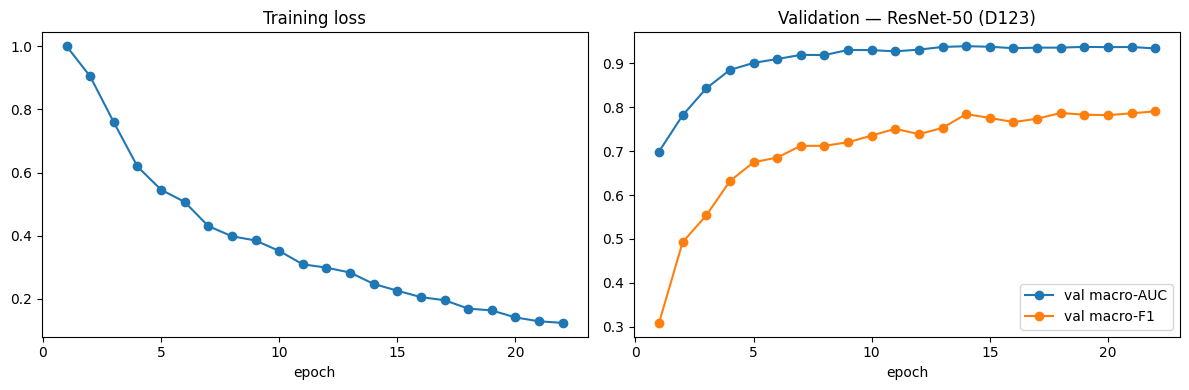

In [12]:
# ============================================================
# Cell 13 — Training curves
# ============================================================
hist = pd.DataFrame(history)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist.epoch, hist.train_loss, marker="o")
ax[0].set_title("Training loss"); ax[0].set_xlabel("epoch")
ax[1].plot(hist.epoch, hist.val_macro_auc, marker="o", label="val macro-AUC")
ax[1].plot(hist.epoch, hist.val_macro_f1,  marker="o", label="val macro-F1")
ax[1].set_title(f"Validation — ResNet-50 ({EXPERIMENT})")
ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{RUN_DIR}/curves.png", dpi=150); plt.show()

In [13]:
# ============================================================
# Cell 14 — Bootstrap 95% confidence intervals (AUC)
# ============================================================
all_test_preds = pd.concat(test_predictions, ignore_index=True)
rng = np.random.default_rng(SEED)
N_BOOTSTRAP = 1000
ci_rows = []

for test_name, g in all_test_preds.groupby("test_set", sort=False):
    y_true = g[CLASSES].values
    y_prob = g[[f"prob_{c}" for c in CLASSES]].values
    n = len(g)
    boot = {c: [] for c in CLASSES + ["macro"]}
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, n, n)
        yt, yp = y_true[idx], y_prob[idx]
        aucs = [roc_auc_score(yt[:, j], yp[:, j]) if 0 < yt[:, j].sum() < n else np.nan
                for j in range(len(CLASSES))]
        for c, a in zip(CLASSES, aucs):
            if not np.isnan(a):
                boot[c].append(a)
        if not np.isnan(aucs).any():
            boot["macro"].append(np.mean(aucs))
    point = {c: roc_auc_score(y_true[:, j], y_prob[:, j]) for j, c in enumerate(CLASSES)}
    point["macro"] = np.mean(list(point.values()))
    for c in CLASSES + ["macro"]:
        lo, hi = np.percentile(boot[c], [2.5, 97.5])
        ci_rows.append({"test_set": test_name, "class": c, "AUC": point[c],
                        "CI_low": lo, "CI_high": hi})

auc_ci = pd.DataFrame(ci_rows)
auc_ci["AUC [95% CI]"] = auc_ci.apply(
    lambda r: f"{r.AUC:.3f} [{r.CI_low:.3f}-{r.CI_high:.3f}]", axis=1)
display(auc_ci.pivot(index="class", columns="test_set", values="AUC [95% CI]")
              .reindex(CLASSES + ["macro"]))
auc_ci.round(4).to_csv(f"{RUN_DIR}/auc_bootstrap_ci.csv", index=False)
print("Saved:", f"{RUN_DIR}/auc_bootstrap_ci.csv")

test_set,D123_in_domain,D1_test,D2_test,D3_test
class,,,,
Normal,0.896 [0.877-0.912],0.801 [0.767-0.832],0.973 [0.947-0.990],0.982 [0.968-0.994]
DR,0.911 [0.894-0.927],0.825 [0.791-0.854],0.970 [0.946-0.987],0.996 [0.991-0.999]
Glaucoma,0.941 [0.915-0.964],0.905 [0.838-0.962],0.963 [0.911-0.995],0.941 [0.905-0.973]
AMD,0.947 [0.916-0.974],0.910 [0.837-0.965],0.950 [0.902-0.987],0.997 [0.991-1.000]
Myopia,0.996 [0.991-0.999],0.996 [0.989-1.000],0.998 [0.991-1.000],0.996 [0.990-1.000]
macro,0.938 [0.927-0.949],0.887 [0.862-0.909],0.971 [0.953-0.984],0.983 [0.973-0.990]


Saved: /kaggle/working/ResNet50_D123/auc_bootstrap_ci.csv
